# Payment Instrument Performance Analysis
How does each payment instrument perform in terms of size, transaction value, growth and stability?

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

DATA_PATH = Path("../Data/Cleaned/Nepal_Online_Payment_System.csv")

df = pd.read_csv(DATA_PATH)
df["period_end"] = pd.to_datetime(df["period_end"])

nepali_month_order = [
    "Baisakh", "Jestha", "Asar", "Saun",
    "Bhadau", "Asoj", "Kartik", "Mangsir",
    "Pus", "Magh", "Falgun", "Chaitra"
]

df["bs_month"] = pd.Categorical(
    df["bs_month"],
    categories=nepali_month_order,
    ordered=True
)

df.shape

(645, 11)

### What data is available for each instrument?

In [3]:
total_months = df["period_end"].nunique()

instrument_profile = (
    df.groupby(["category", "instrument"])
    .agg(
        first_month=("period_end", "min"),
        last_month=("period_end", "max"),
        months_reported=("period_end", "nunique"),
        flagged_months=("is_flagged", "sum")
    )
    .reset_index()
    .sort_values(["category", "instrument"])
)

instrument_profile["coverage_pct"] = (
    instrument_profile["months_reported"] / total_months * 100
).round(1)

instrument_profile

,category,instrument,first_month,last_month,months_reported,flagged_months,coverage_pct
0,Banking channels,Branchless Banking,2023-07-01,2026-10-01,40,0,100.0
1,Banking channels,Internet Banking,2023-07-01,2026-10-01,40,1,100.0
2,Banking channels,Mobile Banking,2023-07-01,2026-10-01,40,1,100.0
3,Cards,Credit Cards,2023-07-01,2026-10-01,40,0,100.0
4,Cards,Debit Cards,2023-07-01,2026-10-01,40,0,100.0
5,Cards,Prepaid Cards,2023-07-01,2026-10-01,40,0,100.0
6,Cash,ATM Cash Withdrawal,2023-07-01,2026-10-01,40,0,100.0
7,Clearing,ECC (Cheque Clearing),2023-07-01,2026-10-01,40,0,100.0
8,Instant payments,Faster Payment Systems,2023-07-01,2026-10-01,31,0,77.5
9,Interbank / large value,RTGS,2023-07-01,2026-10-01,40,0,100.0


### Observations: Data coverage
1. The dataset has 17 payment instruments in 10 categories, covering 40 months (Jul 2023 to Oct 2026). All of them are still reporting in the latest month.
2. 14 instruments have complete coverage (40 months).
3. Three instruments have gaps: Faster Payment Systems (31 months, missing Aug 2023 to Apr 2024), Other Retail Payments (29 months, missing Aug 2023 to Jun 2024) and Cross Border QR Acquiring (25 months, started in Oct 2024). Their historical totals and growth cannot be compared directly with the other instruments.
4. 12 months are flagged: IPS has 10 (count spikes), Mobile Banking has 1 (source revision in Nov 2023) and Internet Banking has 1 (large amount drop in Oct 2026, possibly preliminary).
5. Because of these gaps, comparisons of current size use the last 12 months (all 17 instruments report), and growth comparisons are made carefully for the three partial instruments.

### Which instruments matter most today? (last 12 months)
The last 12 months (Nov 2025 to Oct 2026) are used because all 17 instruments report in that period, so there are no gaps or partial years to distort the comparison.

In [4]:
latest_month = df["period_end"].max()
start_month = latest_month - pd.DateOffset(months=11)

recent = df[df["period_end"] >= start_month]

recent_summary = (
    recent.groupby(["category", "instrument"])
    .agg(
        months=("period_end", "nunique"),
        total_txn_count=("txn_count", "sum"),
        total_amount_npr_million=("txn_amount_npr_million", "sum")
    )
    .reset_index()
)

recent_summary["count_share_pct"] = (
    recent_summary["total_txn_count"] / recent_summary["total_txn_count"].sum() * 100
)
recent_summary["amount_share_pct"] = (
    recent_summary["total_amount_npr_million"] / recent_summary["total_amount_npr_million"].sum() * 100
)

recent_summary["total_count_million"] = recent_summary["total_txn_count"] / 1_000_000
recent_summary["total_amount_npr_trillion"] = recent_summary["total_amount_npr_million"] / 1_000_000

recent_summary = recent_summary.sort_values("count_share_pct", ascending=False)

recent_summary[
    ["category", "instrument", "months", "total_count_million",
     "count_share_pct", "total_amount_npr_trillion", "amount_share_pct"]
].round(2)

,category,instrument,months,total_count_million,count_share_pct,total_amount_npr_trillion,amount_share_pct
2,Banking channels,Mobile Banking,12,859.26,30.53,6.94,5.18
15,Wallet & QR,QR-Based Payments,12,694.53,24.68,1.81,1.35
16,Wallet & QR,Wallet,12,573.69,20.39,0.61,0.45
8,Instant payments,Faster Payment Systems,12,237.22,8.43,6.79,5.06
13,Other retail,Other Retail Payments,12,134.83,4.79,7.64,5.70
4,Cards,Debit Cards,12,121.09,4.30,0.94,0.70
6,Cash,ATM Cash Withdrawal,12,114.69,4.08,0.91,0.68
10,Interbank / retail,IPS,12,35.99,1.28,3.67,2.74
7,Clearing,ECC (Cheque Clearing),12,13.32,0.47,6.84,5.10
12,Merchant & e-commerce,Point of Sales (POS),12,8.99,0.32,0.05,0.04


### Observations: Instrument size (last 12 months, Nov 2025 to Oct 2026)
1. Three instruments carry most of the transaction count: Mobile Banking (30.53%), QR-Based Payments (24.68%) and Wallet (20.39%), together 75.60%. Adding Faster Payment Systems (8.43%) brings the top four to about 84%.
2. RTGS carries 72.74% of the transaction amount (NPR 97.55 trillion) with only 0.03% of the count (0.86 million transactions).
3. After RTGS, value is spread fairly evenly: Other Retail Payments (5.70%), Mobile Banking (5.18%), ECC (5.10%) and Faster Payment Systems (5.06%).
4. Count and value rankings are very different. Mobile Banking, QR and Wallet lead by count but together hold only about 7% of the amount, while ECC has just 0.47% of the count but 5.10% of the amount.
5. Compared with the full-period shares in notebook 02 (a different period, so indicative), QR-Based Payments has risen (19.67% to 24.68% of count), while Mobile Banking (31.56% to 30.53%) and Wallet (20.95% to 20.39%) have slipped slightly.

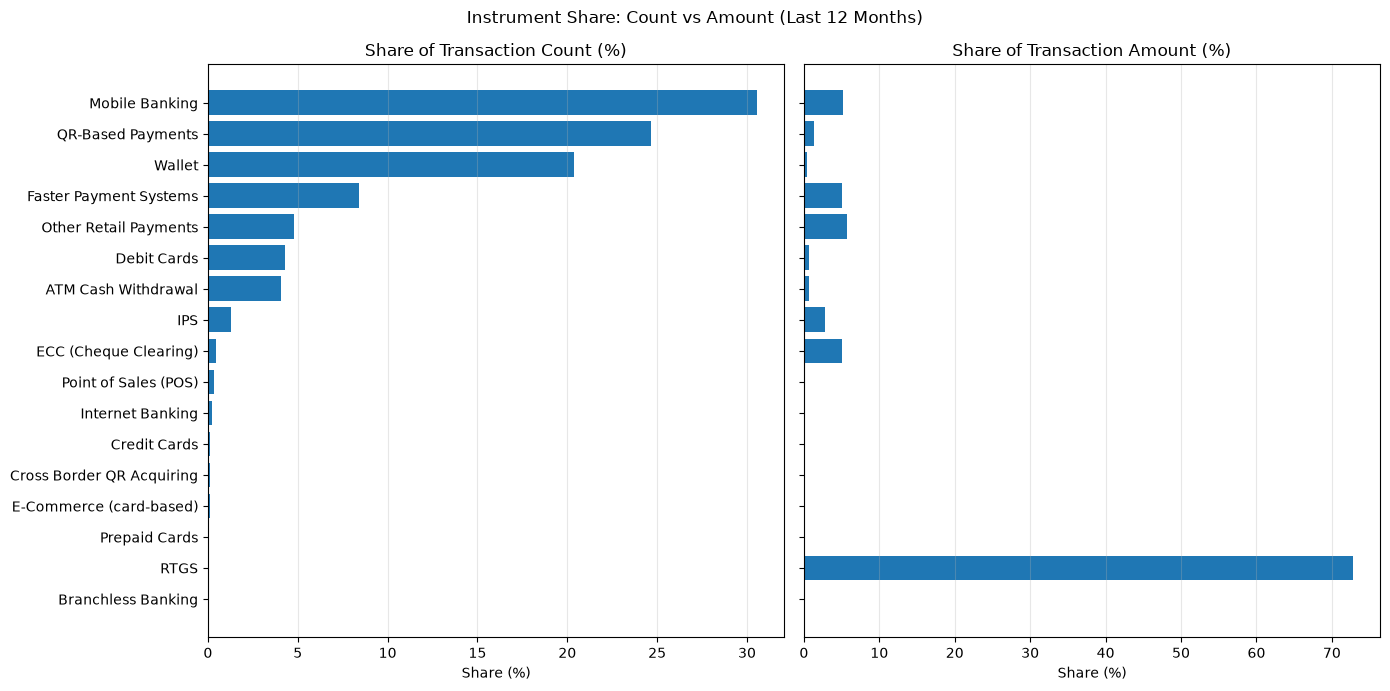

In [5]:
plot_df = recent_summary.sort_values("count_share_pct")

fig, axes = plt.subplots(1, 2, figsize=(14, 7), sharey=True)

axes[0].barh(plot_df["instrument"], plot_df["count_share_pct"])
axes[0].set_title("Share of Transaction Count (%)")
axes[0].set_xlabel("Share (%)")

axes[1].barh(plot_df["instrument"], plot_df["amount_share_pct"])
axes[1].set_title("Share of Transaction Amount (%)")
axes[1].set_xlabel("Share (%)")

for ax in axes:
    ax.grid(axis="x", alpha=0.3)

plt.suptitle("Instrument Share: Count vs Amount (Last 12 Months)")
plt.tight_layout()
plt.show()

### How big is a typical transaction for each instrument, and how stable is it?
Average transaction value (NPR) shows the size of a typical payment for each instrument. Median is used for the typical value because it is not distorted by one-off months. The coefficient of variation (CV) shows how much the value swings from month to month (low = stable).

In [6]:
ticket_stats = (
    df.groupby(["category", "instrument"])["avg_txn_value_npr"]
    .agg(
        median_value="median",
        mean_value="mean",
        min_value="min",
        max_value="max",
        std_value="std"
    )
    .reset_index()
)

ticket_stats["cv_pct"] = ticket_stats["std_value"] / ticket_stats["mean_value"] * 100

# Last 12 months: total amount divided by total count
recent_ticket = recent_summary[["instrument", "total_txn_count", "total_amount_npr_million"]].copy()
recent_ticket["recent_avg_value_npr"] = (
    recent_ticket["total_amount_npr_million"] * 1_000_000
    / recent_ticket["total_txn_count"]
)

ticket_stats = (
    ticket_stats
    .merge(recent_ticket[["instrument", "recent_avg_value_npr"]], on="instrument")
    .sort_values("median_value", ascending=False)
)

ticket_stats[
    ["category", "instrument", "median_value", "recent_avg_value_npr",
     "min_value", "max_value", "cv_pct"]
].style.format({
    "median_value": "{:,.0f}",
    "recent_avg_value_npr": "{:,.0f}",
    "min_value": "{:,.0f}",
    "max_value": "{:,.0f}",
    "cv_pct": "{:.1f}"
})

,category,instrument,median_value,recent_avg_value_npr,min_value,max_value,cv_pct
9,Interbank / large value,RTGS,"79,964,058","114,040,052","35,793,924","256,872,233",56.8
7,Clearing,ECC (Cheque Clearing),"498,830","513,964","453,541","558,237",4.7
10,Interbank / retail,IPS,"109,197","102,095","43,739","267,037",43.7
13,Other retail,Other Retail Payments,"57,859","56,684","46,408","87,386",13.5
1,Banking channels,Internet Banking,"45,069","38,648","21,296","54,981",14.9
8,Instant payments,Faster Payment Systems,"29,859","28,612","26,293","32,862",5.4
0,Banking channels,Branchless Banking,"22,095","22,839","18,961","24,092",5.9
2,Banking channels,Mobile Banking,"8,150","8,080","7,023","9,127",5.6
6,Cash,ATM Cash Withdrawal,"8,142","7,920","7,466","9,631",5.3
4,Cards,Debit Cards,"7,916","7,725","7,246","9,361",5.2


### Observations: Transaction size and stability
1. Transaction sizes span almost five orders of magnitude: RTGS has a median of about NPR 80 million per transaction, ECC about NPR 0.5 million, and Wallet only about NPR 1,100 (roughly 70,000 times smaller than RTGS).
2. Digital retail channels are small-ticket. Mobile Banking, ATM Cash Withdrawal and Debit Cards all sit at about NPR 7,900 to 8,150 per transaction, and QR-Based Payments, Cross Border QR and Wallet are the smallest (about NPR 1,100 to 2,800). This explains why Wallet and QR have a high share of count but a very small share of amount.
3. ECC is the most stable instrument (CV 4.7%, range NPR 454K to 558K), followed by ATM, Debit Cards, Faster Payment Systems and Mobile Banking (all about 5% to 6%).
4. RTGS (CV 56.8%) and IPS (CV 43.7%) are the least stable. RTGS ranges from NPR 35.8 million to 256.9 million per transaction, so its recent average (114 million) is far from its median (80 million). IPS is affected by its flagged count spikes.
5. Internet Banking's transaction value has been declining: its last-12-month average (NPR 38,648) is about 14% below its median (45,069), in line with the yearly averages in notebook 02 (about 48K down to 37K).
6. Prepaid Cards (CV 17.8%) and E-Commerce (CV 17.1%) are the least stable of the small-ticket instruments.

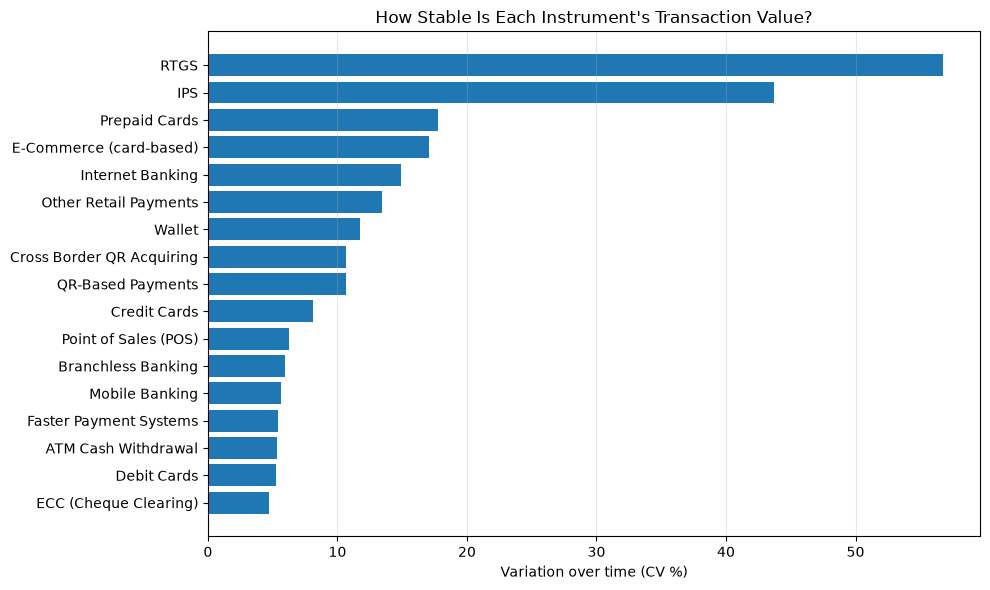

In [7]:
plot_df = ticket_stats.sort_values("cv_pct")

plt.figure(figsize=(10, 6))
plt.barh(plot_df["instrument"], plot_df["cv_pct"])
plt.xlabel("Variation over time (CV %)")
plt.title("How Stable Is Each Instrument's Transaction Value?")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

### Observations: Stability of transaction value
1. ECC (CV 4.7%) is the most stable instrument, and Debit Cards, ATM Cash Withdrawal, Faster Payment Systems, Mobile Banking and Branchless Banking are also very stable (about 5% to 6%).
2. RTGS (56.8%) and IPS (43.7%) swing the most, far above every other instrument.
3. The rest are in the middle, with CV about 8% to 18%. Prepaid Cards (17.8%) and E-Commerce (17.1%) are the highest of this group.

### Which instruments grew the most?
Growth is measured by comparing 12-month totals, so seasonal effects cancel out. Recent growth compares the last 12 months with the 12 months before. Long-run growth compares the last 12 months with the first 12 months of the dataset, and is shown only for instruments that reported in all of those first 12 months.

In [8]:
latest_month = df["period_end"].max()
last_start = latest_month - pd.DateOffset(months=11)      # Nov 2025
prev_start = last_start - pd.DateOffset(months=12)        # Nov 2024
first_end = df["period_end"].min() + pd.DateOffset(months=11)   # Jun 2024

last_12 = df[df["period_end"] >= last_start]
prev_12 = df[(df["period_end"] >= prev_start) & (df["period_end"] < last_start)]
first_12 = df[df["period_end"] <= first_end]

def window_summary(data, label):
    return (
        data.groupby("instrument")
        .agg(count=("txn_count", "sum"), months=("period_end", "nunique"))
        .add_prefix(label + "_")
    )

growth = (
    window_summary(first_12, "first")
    .join(window_summary(prev_12, "prev"))
    .join(window_summary(last_12, "last"))
)

growth["recent_growth_pct"] = (growth["last_count"] / growth["prev_count"] - 1) * 100

growth["long_run_growth_pct"] = np.where(
    growth["first_months"] == 12,
    (growth["last_count"] / growth["first_count"] - 1) * 100,
    np.nan
)

for col in ["first_count", "prev_count", "last_count"]:
    growth[col.replace("count", "count_million")] = growth[col] / 1_000_000

growth = growth.sort_values("recent_growth_pct", ascending=False).reset_index()

growth[
    ["instrument", "first_months", "prev_months", "last_months",
     "first_count_million", "prev_count_million", "last_count_million",
     "recent_growth_pct", "long_run_growth_pct"]
].style.format({
    "first_count_million": "{:,.2f}",
    "prev_count_million": "{:,.2f}",
    "last_count_million": "{:,.2f}",
    "recent_growth_pct": "{:.1f}",
    "long_run_growth_pct": "{:.1f}"
})

,instrument,first_months,prev_months,last_months,first_count_million,prev_count_million,last_count_million,recent_growth_pct,long_run_growth_pct
0,QR-Based Payments,12,12,12,158.29,380.34,694.53,82.6,338.8
1,Other Retail Payments,1,12,12,3.68,96.05,134.83,40.4,nan
2,E-Commerce (card-based),12,12,12,1.42,2.20,2.98,35.6,109.6
3,Wallet,12,12,12,283.26,426.82,573.69,34.4,102.5
4,Faster Payment Systems,3,12,12,34.42,183.45,237.22,29.3,nan
5,Mobile Banking,12,12,12,407.28,669.59,859.26,28.3,111.0
6,Internet Banking,12,12,12,3.48,5.57,6.94,24.7,99.6
7,Credit Cards,12,12,12,3.22,3.30,3.85,16.5,19.3
8,IPS,12,12,12,24.12,31.17,35.99,15.4,49.2
9,ECC (Cheque Clearing),12,12,12,12.02,12.49,13.32,6.6,10.8


### Observations: Growth by instrument
Recent growth = last 12 months vs the 12 months before. Long-run growth = last 12 months vs the first 12 months (only for instruments with a complete first year).

1. QR-Based Payments grew fastest by far: +82.6% in the last year and +338.8% over the long run (158M to 695M transactions a year).
2. Other Retail Payments (+40.4%), E-Commerce (+35.6%), Wallet (+34.4%), Faster Payment Systems (+29.3%) and Mobile Banking (+28.3%) also grew strongly. E-Commerce is growing from a very small base (about 3M transactions a year). Long-run growth for Other Retail and Faster Payment Systems cannot be measured, because they did not report in the first year.
3. Over the long run, Mobile Banking (+111.0%), E-Commerce (+109.6%), Wallet (+102.5%) and Internet Banking (+99.6%) roughly doubled.
4. Prepaid Cards has stalled: +55.3% over the long run but only +0.8% in the last year. RTGS (+2.3%) and ECC (+6.6%) grow slowly.
5. ATM Cash Withdrawal (-9.1%), Debit Cards (-10.4%), Branchless Banking (-12.0%) and Point of Sales (-24.7%) all fell in the last 12 months. ATM, Debit Cards and Branchless Banking were already 11% to 13% below their first year. Cash and card channels are losing ground while QR, wallet and mobile grow.
6. IPS grew +15.4% recently, but this is probably overstated because its last 12 months contain more flagged spike months (4 vs 2). This is checked in the flagged-months step.

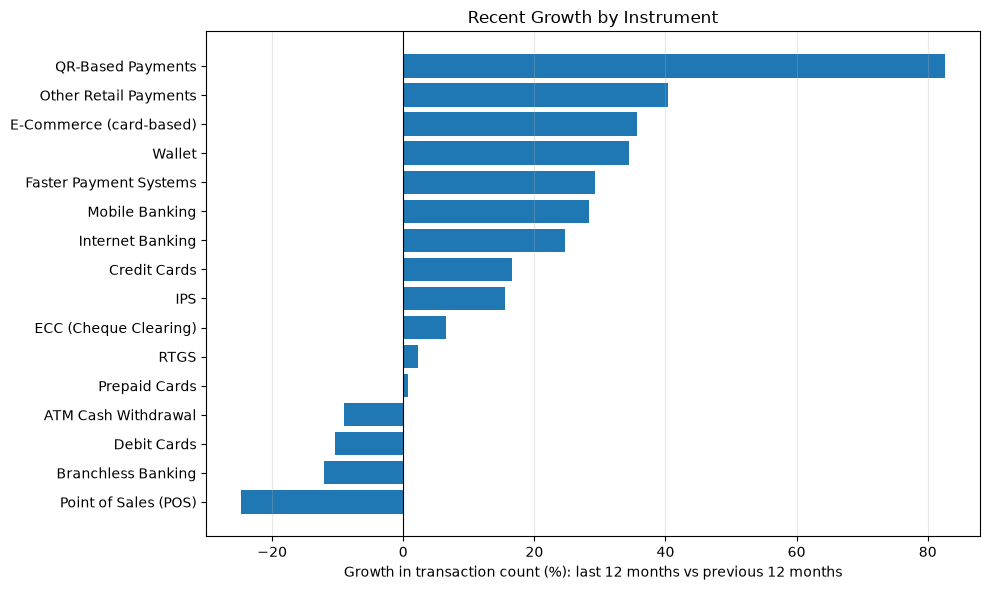

In [9]:
plot_df = growth.sort_values("recent_growth_pct")

plt.figure(figsize=(10, 6))
plt.barh(plot_df["instrument"], plot_df["recent_growth_pct"])
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Growth in transaction count (%): last 12 months vs previous 12 months")
plt.title("Recent Growth by Instrument")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

### Which instruments are steady and which are erratic?
Month-to-month stability of transaction count is measured for Oct 2024 to Oct 2026, the only period where all 17 instruments report every month.

In [10]:
era = df[df["period_end"] >= "2024-10-01"]

count_by_month = era.pivot(index="period_end", columns="instrument", values="txn_count")

print(count_by_month.shape)               # expect (25, 17)
print(count_by_month.isna().sum().sum())  # expect 0

mom = count_by_month.pct_change() * 100

t = np.arange(len(count_by_month))

def deviation_from_trend(series):
    y = np.log(series)
    trend = np.polyval(np.polyfit(t, y, 1), t)
    return (y - trend).std() * 100

stability = pd.DataFrame({
    "months_with_fall_pct": (mom.iloc[1:] < 0).mean() * 100,
    "worst_monthly_fall_pct": mom.min(),
    "biggest_monthly_jump_pct": mom.max(),
    "deviation_from_trend_pct": count_by_month.apply(deviation_from_trend),
}).sort_values("deviation_from_trend_pct")

stability.round(1)

(25, 17)
0


,months_with_fall_pct,worst_monthly_fall_pct,biggest_monthly_jump_pct,deviation_from_trend_pct
instrument,,,,
ATM Cash Withdrawal,45.8,-15.4,7.9,4.7
Wallet,33.3,-7.1,13.3,4.9
Debit Cards,45.8,-15.1,7.9,5.1
Faster Payment Systems,29.2,-11.4,13.9,5.2
Mobile Banking,37.5,-18.8,19.1,7.1
QR-Based Payments,16.7,-9.1,20.9,7.6
Prepaid Cards,37.5,-16.8,12.3,9.7
RTGS,54.2,-24.8,34.0,10.3
Other Retail Payments,33.3,-23.2,33.0,10.8
